# Comedy Show: learn decisions with a tree

Original tutorial: [W3Schools: Decision Tree](https://www.w3schools.com/python/python_ml_decision_tree.asp).

Use `Pandas` and `Scikit-Learn` to create a Decision Tree classifier to predict whether an audience will attend a comedy show. This small example makes the learned rules easy to inspect.

### Topics
- Load a CSV table
- Encode categories and a binary target
- Train and visualize a Decision Tree
- Compare predictions for two comedians

**Question for the lesson:** Which features guide the decision to go to a show?

> **Estimated time: 60 min**

## 1 · Import the tools

Pandas loads the table. We import scikit-learn and Matplotlib to train and draw the tree.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier

## 2 · Load and inspect the table

Open `data.csv` from the same folder as this notebook. Each row describes a comedian and whether the audience decided to go to the show (`Go`).

In [2]:
df = pd.read_csv("data.csv")
df

,Age,Experience,Rank,Nationality,Go
0,36,10,9,UK,NO
1,42,12,4,USA,NO
2,23,4,6,N,NO
3,52,4,4,USA,NO
4,43,21,8,USA,YES
5,44,14,5,UK,NO
6,66,3,7,N,YES
7,35,14,9,UK,YES
8,52,13,7,N,YES
9,35,5,9,N,YES


## 3 · Convert categories into numbers

Encode `Nationality` as `UK = 0`, `USA = 1`, and `N = 2`. Encode the target as `YES = 1` and `NO = 0`. These nationality codes are labels; their numerical order does not represent a ranking.

In [3]:
d = {'UK': 0, 'USA': 1, 'N': 2}
df['Nationality'] = df['Nationality'].map(d)
d = {'YES': 1, 'NO': 0}
df['Go'] = df['Go'].map(d)

df

,Age,Experience,Rank,Nationality,Go
0,36,10,9,0,0
1,42,12,4,1,0
2,23,4,6,2,0
3,52,4,4,1,0
4,43,21,8,1,1
5,44,14,5,0,0
6,66,3,7,2,1
7,35,14,9,0,1
8,52,13,7,2,1
9,35,5,9,2,1


## 4 · Choose features and target

`X` contains age, experience, rank, and nationality. `y` contains the attendance decision to predict. Keep this feature order when supplying new rows.

In [4]:
features = ['Age', 'Experience', 'Rank', 'Nationality']

X = df[features]
y = df['Go']

display(X)
display(y)

,Age,Experience,Rank,Nationality
0,36,10,9,0
1,42,12,4,1
2,23,4,6,2
3,52,4,4,1
4,43,21,8,1
5,44,14,5,0
6,66,3,7,2
7,35,14,9,0
8,52,13,7,2
9,35,5,9,2


0     0
1     0
2     0
3     0
4     1
5     0
6     1
7     1
8     1
9     1
10    0
11    1
12    1
Name: Go, dtype: int64

## 5 · Train and visualize the Decision Tree

A classifier learns if/then rules that separate the two target classes. The code fits the tree on every row, then draws its splits. Follow a path from the root to a leaf: `samples` counts training rows, `value` counts rows in each class, and lower Gini impurity means a purer node.

There is no held-out test set here, so the diagram demonstrates learned rules rather than measured performance on unseen data.

[Text(0.3333333333333333, 0.875, 'Rank <= 6.5\ngini = 0.497\nsamples = 13\nvalue = [6, 7]'),
 Text(0.16666666666666666, 0.625, 'gini = 0.0\nsamples = 5\nvalue = [5, 0]'),
 Text(0.25, 0.75, 'True  '),
 Text(0.5, 0.625, 'Experience <= 9.5\ngini = 0.219\nsamples = 8\nvalue = [1, 7]'),
 Text(0.41666666666666663, 0.75, '  False'),
 Text(0.3333333333333333, 0.375, 'gini = 0.0\nsamples = 4\nvalue = [0, 4]'),
 Text(0.6666666666666666, 0.375, 'Experience <= 11.5\ngini = 0.375\nsamples = 4\nvalue = [1, 3]'),
 Text(0.5, 0.125, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.8333333333333334, 0.125, 'gini = 0.0\nsamples = 3\nvalue = [0, 3]')]

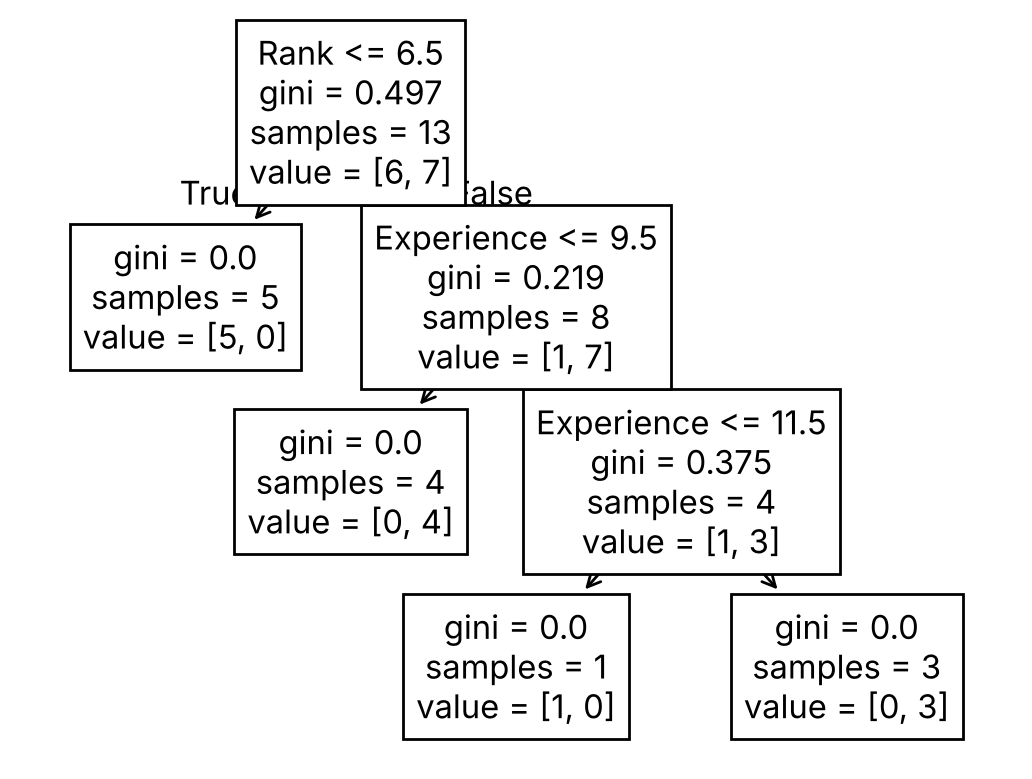

In [5]:
dtree = DecisionTreeClassifier()
dtree = dtree.fit(X, y)

tree.plot_tree(dtree, feature_names=features)

In [6]:
importances = dtree.feature_importances_
importances

array([0.        , 0.27083333, 0.72916667, 0.        ])

## 6 · Predict

In [7]:
sample = pd.DataFrame([{
    'Age': 40,
    'Experience': 10,
    'Rank': 7,
    'Nationality': 1,
}])

print(dtree.predict(sample))

[0]


---
# Exercises

## A · Our data is limited: augment it with synthetic data (`sdv`)

Only 13 real rows are available. `sdv` learns the joint distribution of the table with a **Gaussian copula** (each column's marginal distribution plus the correlations between columns) and samples new, artificial comedians that look statistically similar. `Nationality` and `Go` are integer *codes* of categories, so they are declared `categorical` in the metadata, otherwise `sdv` would treat them as numbers and could generate values such as 0.4 or 1.7.

In [8]:
import numpy as np
import sdv
from sdv.metadata import Metadata
from sdv.single_table import GaussianCopulaSynthesizer

np.random.seed(42)                       # reproducible synthetic sample
df_real = df.copy()                      # the 13 real (already encoded) rows

metadata = Metadata.detect_from_dataframes(data={'comedian': df_real})
for col in ['Nationality', 'Go']:        # integer codes of categories, not quantities
    metadata.update_column(table_name='comedian', column_name=col, sdtype='categorical')

synthesizer = GaussianCopulaSynthesizer(metadata)
synthesizer.fit({'comedian': df_real})
synthetic_data = synthesizer.sample(num_rows=100)['comedian']
synthetic_data = synthetic_data.astype(df_real.dtypes.to_dict())   # keep the integer codes

df_augmented = pd.concat([df_real, synthetic_data], ignore_index=True)
print('real:', len(df_real), '| synthetic:', len(synthetic_data), '| augmented:', len(df_augmented))
display(df_augmented)

/home/claude/venv/lib/python3.13/site-packages/sdv/single_table/base.py:136: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(


real: 13 | synthetic: 100 | augmented: 113


,Age,Experience,Rank,Nationality,Go
0,36,10,9,0,0
1,42,12,4,1,0
2,23,4,6,2,0
3,52,4,4,1,0
4,43,21,8,1,1
...,...,...,...,...,...
108,48,5,5,1,1
109,20,4,6,1,1
110,21,17,6,0,1
111,52,18,9,0,1


In [9]:
# Do the synthetic rows resemble the real ones?
compare = pd.concat({'real': df_real.describe().loc[['mean', 'std', 'min', 'max']].T,
                     'synthetic': synthetic_data.describe().loc[['mean', 'std', 'min', 'max']].T}, axis=1).round(2)
display(compare)
print('Share of Go=1   real: %.2f   synthetic: %.2f' % (df_real['Go'].mean(), synthetic_data['Go'].mean()))

real                    synthetic                   
              mean    std   min   max      mean    std   min   max
Age          39.62  13.26  18.0  66.0     35.24  14.19  18.0  66.0
Experience    8.85   5.73   3.0  21.0     11.58   5.37   4.0  21.0
Rank          6.85   1.91   4.0   9.0      6.76   1.76   4.0   9.0
Nationality   0.92   0.86   0.0   2.0      0.82   0.83   0.0   2.0
Go            0.54   0.52   0.0   1.0      0.63   0.49   0.0   1.0

Share of Go=1   real: 0.54   synthetic: 0.63


Now train a Decision Tree classifier on the **augmented** dataset (real + synthetic rows).

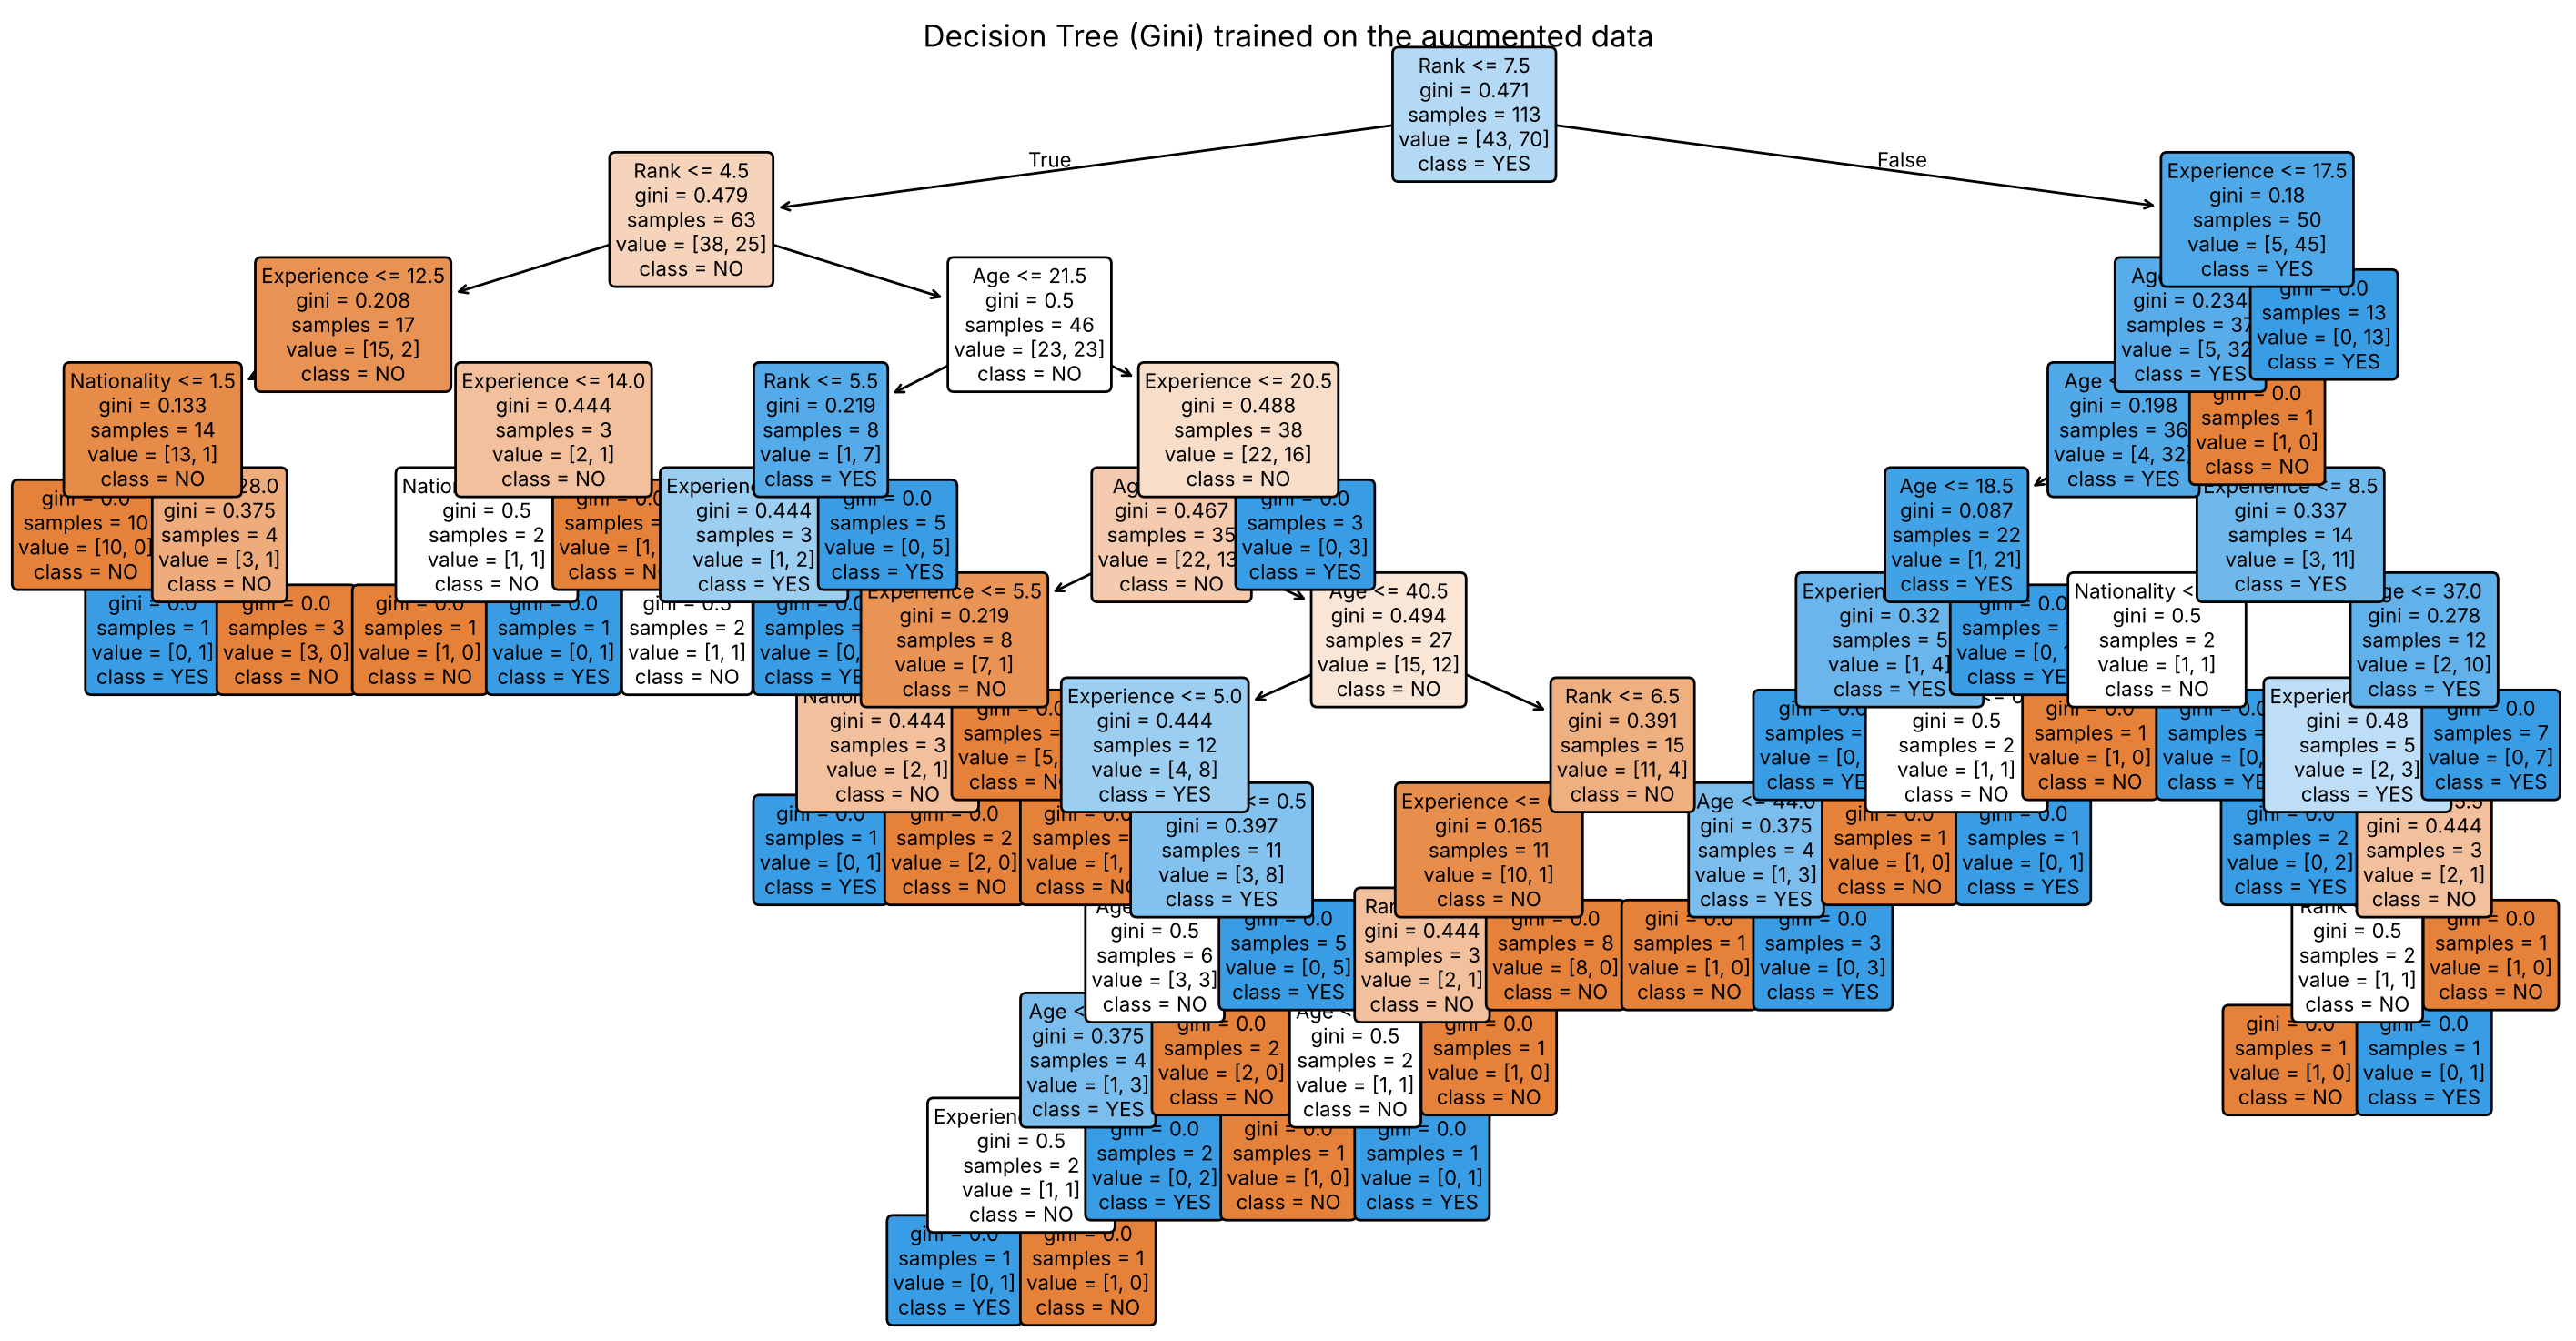

depth: 11 | leaves: 38
prediction for the sample comedian: [1]


In [10]:
X_aug = df_augmented[features]
y_aug = df_augmented['Go']

dtree_aug = DecisionTreeClassifier(random_state=42).fit(X_aug, y_aug)

plt.figure(figsize=(18, 9))
tree.plot_tree(dtree_aug, feature_names=features, class_names=['NO', 'YES'], filled=True, rounded=True, fontsize=8)
plt.title('Decision Tree (Gini) trained on the augmented data'); plt.show()
print('depth:', dtree_aug.get_depth(), '| leaves:', dtree_aug.get_n_leaves())
print('prediction for the sample comedian:', dtree_aug.predict(sample))

### Does augmentation really help? (leave-one-out check on the 13 real rows)

Training accuracy of a tree is meaningless (it can memorise the data), and the synthetic rows are copies of what the model already saw. A fair check is leave-one-out: hold out one **real** comedian, generate synthetic data only from the other 12, train, and predict the held-out one. The synthesizer therefore never sees the held-out row.

In [11]:
import warnings, logging
warnings.filterwarnings('ignore'); logging.disable(logging.WARNING)

hits_real, hits_aug = [], []
for i in df_real.index:
    train_part = df_real.drop(index=i).reset_index(drop=True)
    test_row = df_real.loc[[i]]
    np.random.seed(42)
    md_ = Metadata.detect_from_dataframes(data={'c': train_part})
    for col in ['Nationality', 'Go']:
        md_.update_column(table_name='c', column_name=col, sdtype='categorical')
    syn = GaussianCopulaSynthesizer(md_); syn.fit({'c': train_part})
    synth = syn.sample(num_rows=100)['c'].astype(train_part.dtypes.to_dict())
    aug = pd.concat([train_part, synth], ignore_index=True)

    m_real = DecisionTreeClassifier(random_state=42).fit(train_part[features], train_part['Go'])
    m_aug = DecisionTreeClassifier(random_state=42).fit(aug[features], aug['Go'])
    hits_real.append(int(m_real.predict(test_row[features])[0] == test_row['Go'].iloc[0]))
    hits_aug.append(int(m_aug.predict(test_row[features])[0] == test_row['Go'].iloc[0]))

print('Leave-one-out accuracy, trained on real rows only : %.3f' % np.mean(hits_real))
print('Leave-one-out accuracy, trained on real+synthetic : %.3f' % np.mean(hits_aug))

Leave-one-out accuracy, trained on real rows only : 0.769
Leave-one-out accuracy, trained on real+synthetic : 0.462


**Result: augmentation did not help here.** A tree trained on the 12 real rows classifies the held-out comedian correctly 76.9 % of the time (10 of 13), while the tree trained on real + 100 synthetic rows manages only 46.2 % (6 of 13). The reason: with just 12 rows the Gaussian copula cannot learn a reliable joint distribution, so most of the 100 synthetic rows are noise that outweighs the 12 real ones, and the tree then spends its splits (depth 11, 38 leaves) memorising that noise. Synthetic data can balance or smooth a table when the generator is fitted to enough real data; it cannot create information that the 13 rows do not contain. Treat the augmented tree as a demonstration of the technique, not as a better model.

## B · `criterion='entropy'` instead of `criterion='gini'`

Both trees are trained on the same augmented data with `random_state=42` so that the only difference is the impurity measure.

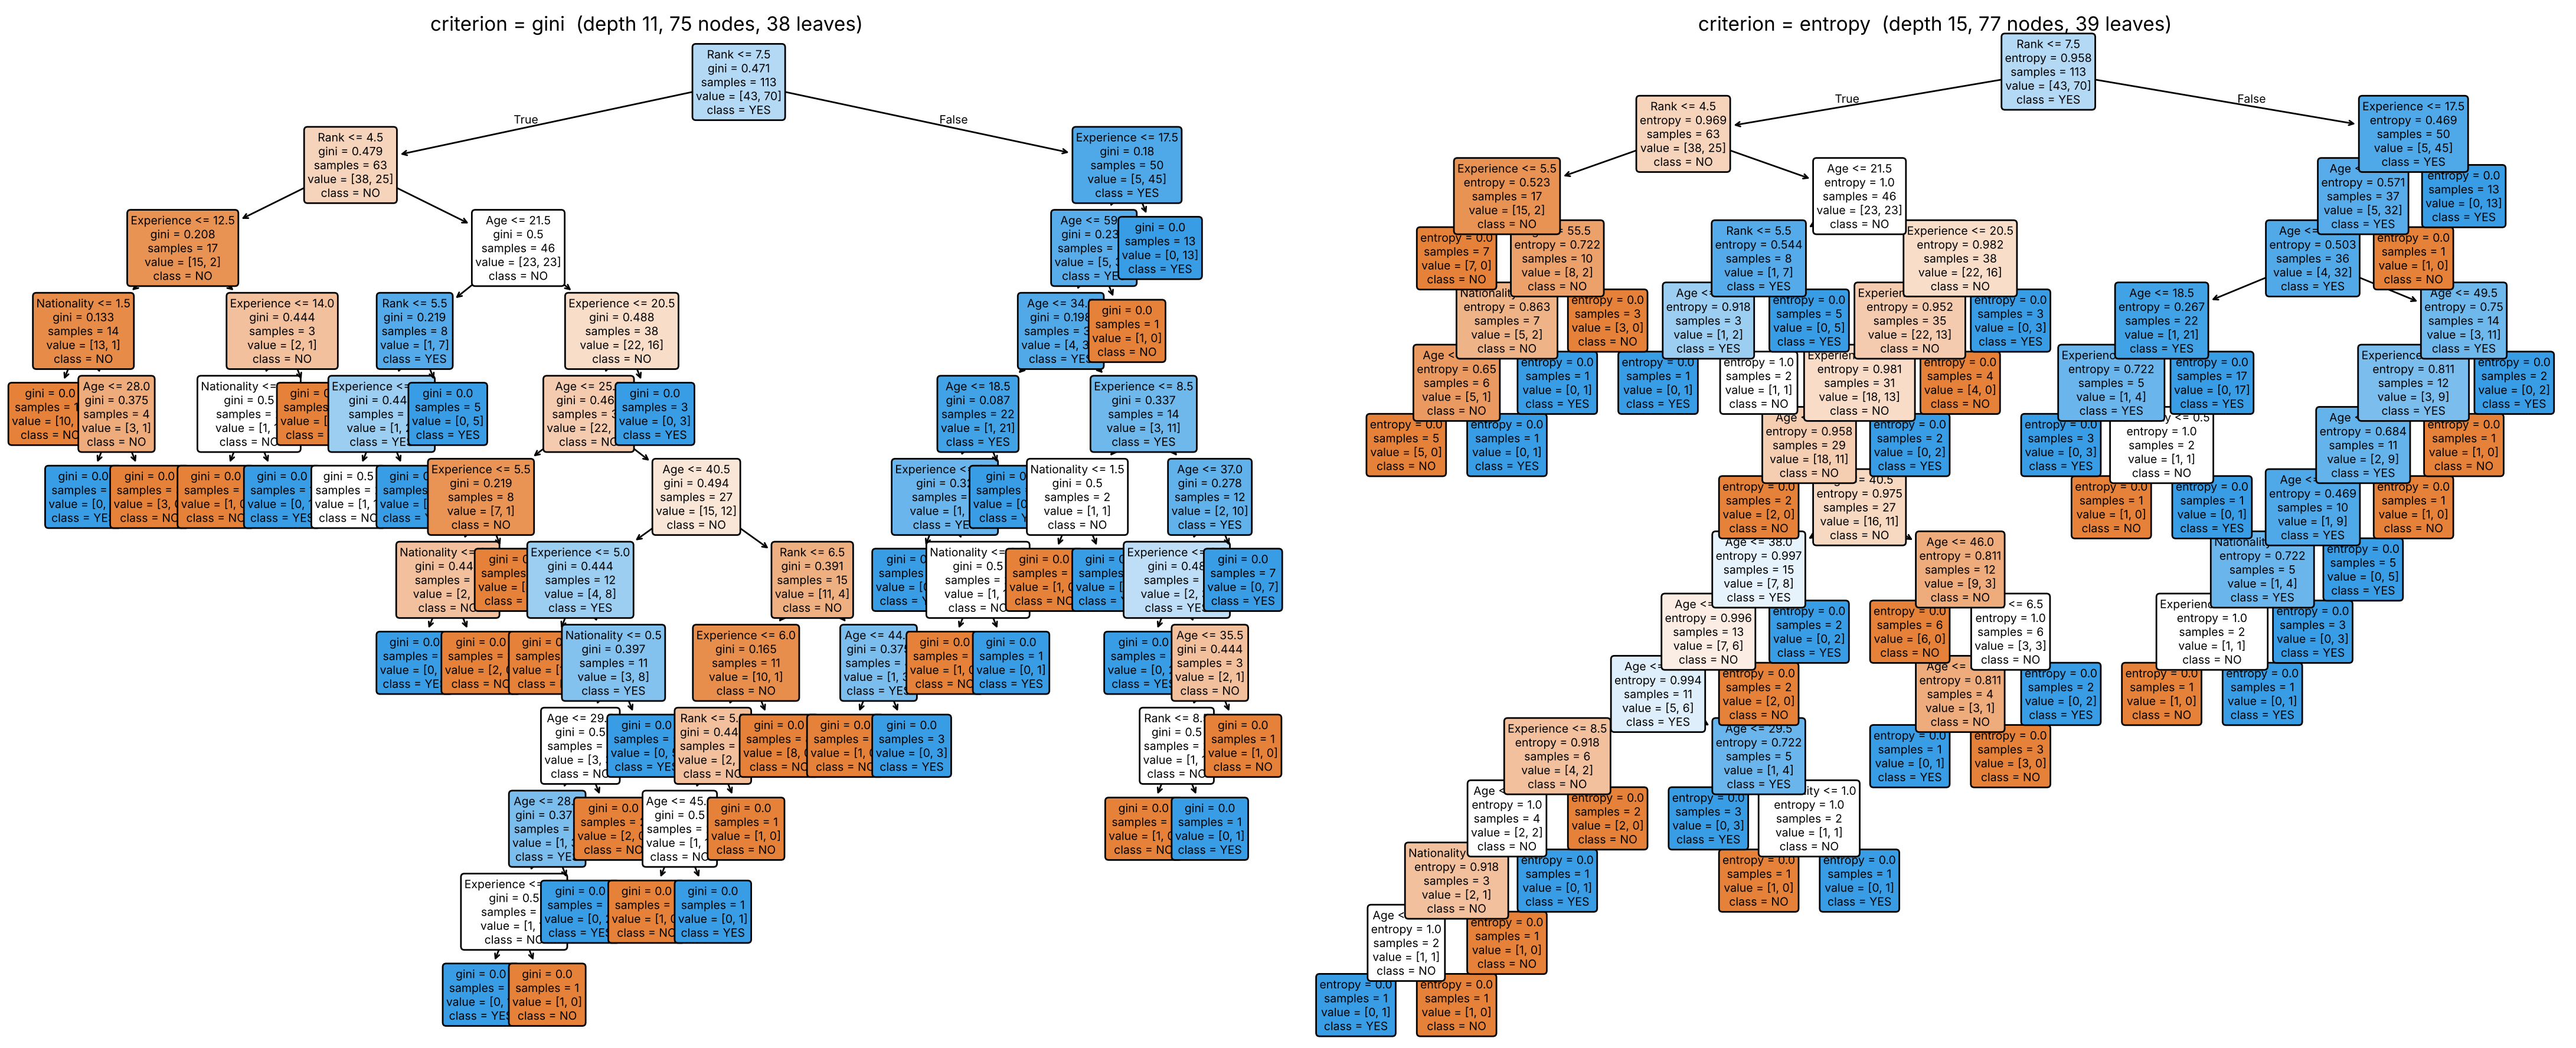

,Depth,Nodes,Leaves,Root split
Gini,11,75,38,Rank <= 7.5
Entropy,15,77,39,Rank <= 7.5


,Gini,Entropy
Age,0.301,0.401
Experience,0.162,0.196
Rank,0.422,0.323
Nationality,0.116,0.080


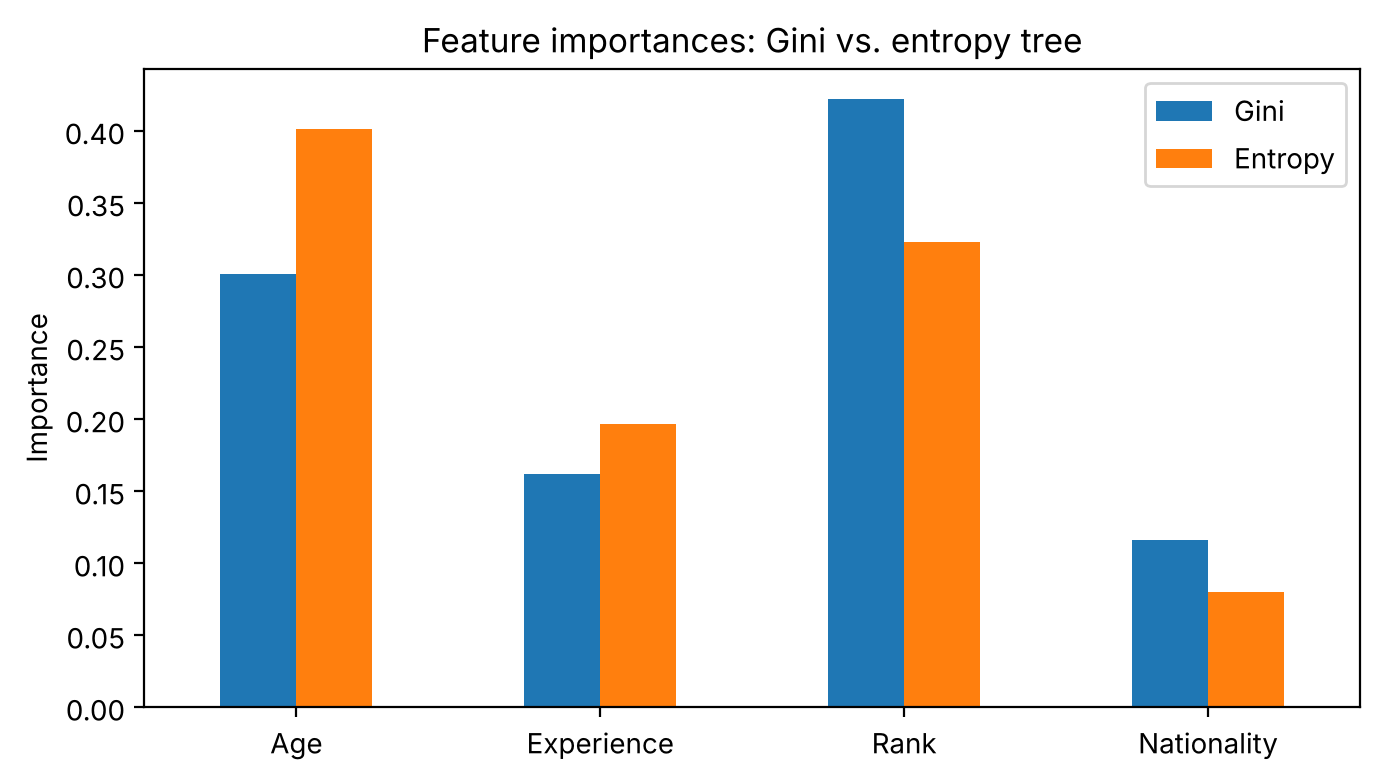

In [12]:
dt_gini = DecisionTreeClassifier(criterion='gini', random_state=42).fit(X_aug, y_aug)
dt_entropy = DecisionTreeClassifier(criterion='entropy', random_state=42).fit(X_aug, y_aug)

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, (name, m) in zip(axes, {'Gini': dt_gini, 'Entropy': dt_entropy}.items()):
    tree.plot_tree(m, feature_names=features, class_names=['NO', 'YES'], filled=True, rounded=True, fontsize=7, ax=ax)
    ax.set_title(f'criterion = {name.lower()}  (depth {m.get_depth()}, {m.tree_.node_count} nodes, {m.get_n_leaves()} leaves)')
plt.tight_layout(); plt.show()

summary = pd.DataFrame({
    'Depth': [m.get_depth() for m in (dt_gini, dt_entropy)],
    'Nodes': [m.tree_.node_count for m in (dt_gini, dt_entropy)],
    'Leaves': [m.get_n_leaves() for m in (dt_gini, dt_entropy)],
    'Root split': [f"{features[m.tree_.feature[0]]} <= {m.tree_.threshold[0]:.1f}" for m in (dt_gini, dt_entropy)],
}, index=['Gini', 'Entropy'])
display(summary)

imp = pd.DataFrame({'Gini': dt_gini.feature_importances_, 'Entropy': dt_entropy.feature_importances_}, index=features)
display(imp.round(3))
imp.plot.bar(figsize=(7, 4), rot=0, title='Feature importances: Gini vs. entropy tree', ylabel='Importance')
plt.tight_layout(); plt.show()

**What is the Gini method and how does it work?** Gini impurity of a node is G = 1 − Σ pₖ², where pₖ is the share of class k in the node: it is the probability that a randomly drawn row would be mislabelled if it were labelled at random according to the node's class mix (0 = pure node, 0.5 = a 50/50 two-class mix). At every node the tree tests all features and thresholds and chooses the split that gives the largest drop in impurity, i.e. the parent's G minus the sample-weighted average G of the two children, and then repeats recursively until the leaves are pure.

**How do the Gini and entropy models differ?** Entropy, H = −Σ pₖ log₂ pₖ, measures the same kind of impurity with a slightly different curve, so on this data both trees start with the same root split (`Rank <= 7.5`) and end up almost the same size (Gini: depth 11, 75 nodes, 38 leaves; entropy: depth 15, 77 nodes, 39 leaves). They differ only in the lower splits: Gini rates `Rank` as the most important feature (0.42) followed by `Age` (0.30), while entropy puts `Age` first (0.40) before `Rank` (0.32); `Experience` (0.16 / 0.20) and `Nationality` (0.12 / 0.08) are least important in both. Since the data is mostly synthetic and tiny, these differences should not be over-interpreted: in practice the two criteria give very similar trees, and Gini is slightly cheaper to compute because it needs no logarithm.

## Key takeaways

- Decision Trees turn feature values into a sequence of decisions.
- Encode text categories and preserve the feature order at prediction time.
- Small changes in an input can move a sample to a different leaf.
- Use a separate test set before making claims about predictive accuracy.